# Physically balanced photoelastic inverse imaging

This active reconstruction uses a real PeGS2 disk ROI under CC BY-NC-SA4.0, with separate MIT Python-source terms. The unknowns are four contact force magnitudes/directions and thickness-integrated principal stress difference. No actual force or stress truth is available.

The published elastic/optical forward is retained. For normal/tangential force components $(n_j,t_j)$ define $F_j=\sqrt{n_j^2+t_j^2}$ and $\alpha_j=\mathrm{atan2}(t_j,n_j)$. The static constraints are $\sum_j(n_j\cos\beta_j+t_j\sin\beta_j)=0$, $\sum_j(-n_j\sin\beta_j+t_j\cos\beta_j)=0$, and $\sum_jt_j=0$ (torque divided by disk radius). These are the force/torque conditions of the2017 paper, SectionIVC/Eq21. SLSQP minimizes the pixel SSE using the PeGS2 published0.96-radius fit mask. The complete stress map extends to the disk outline.

**Explicit correction.** The source optional penalty swaps alpha/beta and does not reliably enforce static balance. Its unmodified original run is archived, with8.7% normalized net force and9.6% torque. The final branch restores the published static constraints; it is not an unchanged upstream optimizer reproduction. Original elastic responses and tensor intermediates are still independently captured. Geometric centre/radius come from a robust fit to the measured red-channel rim, not a half-pixel choice to avoid a singularity. Floating-point acquisition calibration is preserved.

**Visual contract.** Acquisition/corrected intensity/fitted intensity/residual reveal actual data and model mismatch. Original-forward constrained oracle and fresh physical stress maps share a labelled99th-percentile display limit; differences expose port error. Optical-calibration bars, balanced/unbalanced response images, multistart and geometry tables expose stability, physical constraints and limitations. No figure treats inferred forces as truth.

Fresh CPU seconds: 1.3154223000165075
reconstruction (0.9999999999896098, 3.5079598483889804e-08)
forces (0.9999999999922002, 3.4668101953935152e-06)
contact_directions (0.9999999999893701, 4.772940447602352e-06)


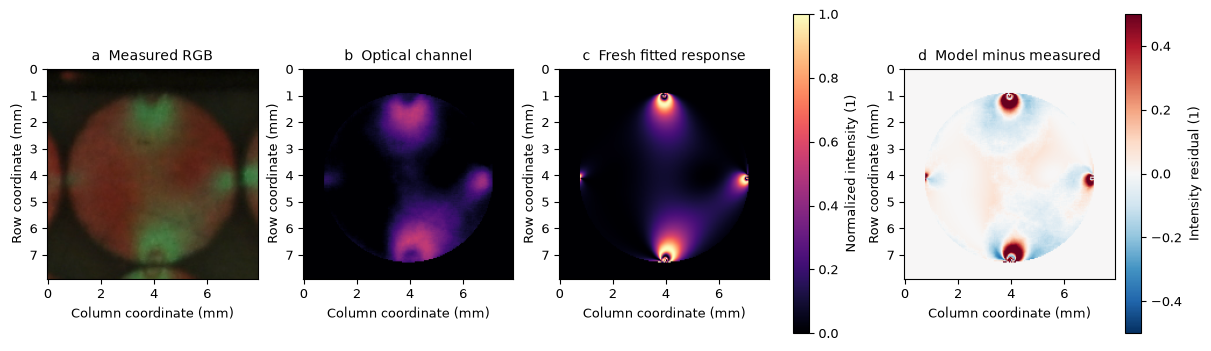

In [1]:
from pathlib import Path
import sys,time,json
import numpy as np
import matplotlib.pyplot as plt
root=Path.cwd() if (Path.cwd()/'src').exists() else Path.cwd().parent
sys.path.insert(0,str(root))
from src.main import run
from src.preprocessing import load_data,prepare,disk_mask
from src.solvers import reconstruct,fit_forces
from src.physics_model import stress_basis,forward
from src.visualization import acquisition_figure,stress_figure,sensitivity_figure,agreement
plt.rcParams.update({'font.size':9,'axes.titlesize':10,'svg.fonttype':'none','pdf.fonttype':42})
data=load_data(root/'data/raw_data.npz');t0=time.perf_counter();fresh=run(root/'data/raw_data.npz',root/'output/reconstruction.npz');runtime=time.perf_counter()-t0
with np.load(root/'notebooks/reference_outputs/upstream.npz') as f:upstream={k:f[k] for k in f.files}
print('Fresh CPU seconds:',runtime)
for k in fresh:print(k,agreement(fresh[k],upstream[k]))
fig=acquisition_figure(data,fresh);plt.show()


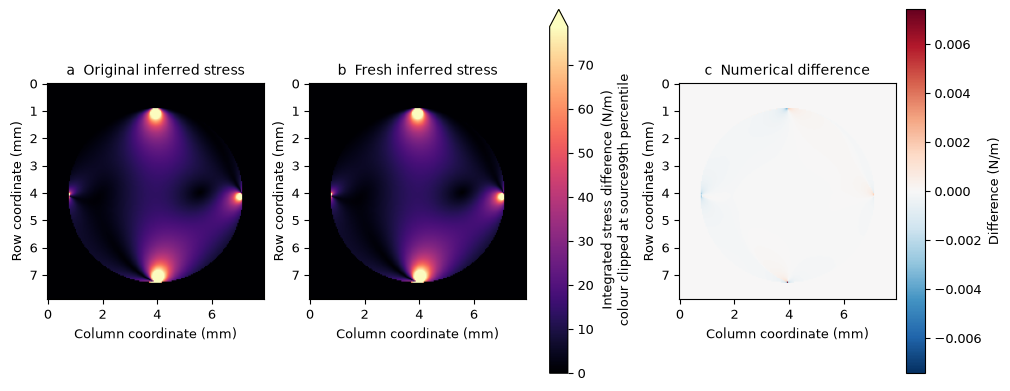

In [2]:
fig=stress_figure(fresh['reconstruction'][0],upstream['reconstruction'][0]);plt.show()


The point-contact model leaves structured optical residuals. The fit excludes the outer4% radius, as in published PeGS2 defaults, because finite contact zones and idealized point contacts differ most there. Stress is nevertheless evaluated on the full declared disk. The original unbalanced optimizer and full-mask constrained failed basins remain archived and explicitly identified; they are not hidden by thresholds.

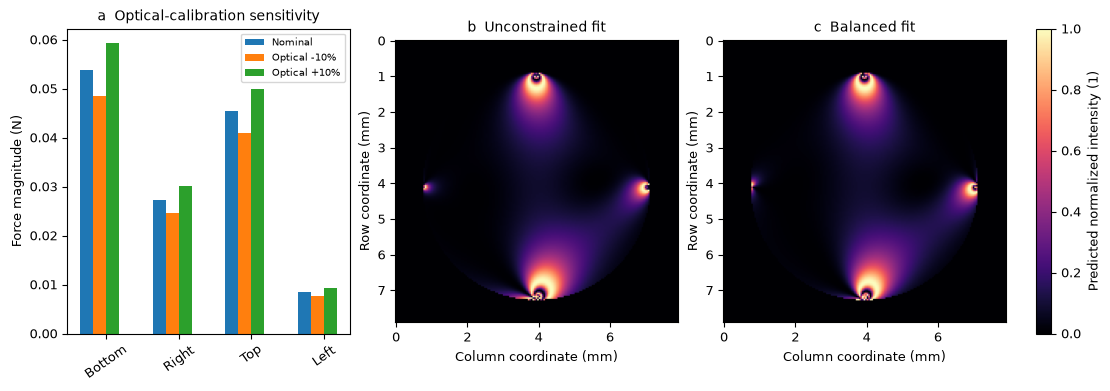

[
  {
    "method": "Nominal",
    "forces_N": [
      0.05387421604239548,
      0.027349265028468673,
      0.045386342214925934,
      0.008421494901043084
    ],
    "alpha_rad": [
      0.3962032562087396,
      -0.46234062890868277,
      -0.015712193886144844,
      -1.2098993525503616
    ],
    "net_force_ratio": 2.5693646470614983e-17,
    "normalized_torque": 2.5693646470614983e-17
  },
  {
    "method": "Optical -10%",
    "forces_N": [
      0.04848674882624384,
      0.024614218706861615,
      0.0408476987031399,
      0.007579635634975819
    ],
    "alpha_rad": [
      0.39620563188333224,
      -0.46235211588863817,
      -0.01570255086214347,
      -1.20990365477481
    ],
    "net_force_ratio": 6.383631721537995e-17,
    "normalized_torque": 0.0
  },
  {
    "method": "Optical +10%",
    "forces_N": [
      0.05926162414400532,
      0.030084060440185457,
      0.04992491360997897,
      0.009263629719518935
    ],
    "alpha_rad": [
      0.39620492206602964,
     

In [3]:
y=prepare(data['rgb']);beta=data['contact_angles']
unbalanced,unbalanced_info=reconstruct(data,balanced=False)
rows={'Nominal':fresh,'Optical -10%':reconstruct(data,fsigma=126.)[0],'Optical +10%':reconstruct(data,fsigma=154.)[0]}
pred=forward(fresh['forces'][0],stress_basis(beta,alpha=fresh['contact_directions'][0]))
pred_unbalanced=forward(unbalanced['forces'][0],stress_basis(beta,alpha=unbalanced['contact_directions'][0]))
fig=sensitivity_figure(rows,{'b  Unconstrained fit':pred_unbalanced,'c  Balanced fit':pred});plt.show()
from src.preprocessing import CENTER,RADIUS
from src.solvers import constraint_matrix
metrics=[]
for name,r in {**rows,'Unconstrained':unbalanced}.items():
    f=r['forces'][0];a=r['contact_directions'][0];q=np.empty(8);q[::2]=f*np.cos(a);q[1::2]=f*np.sin(a);res=constraint_matrix(beta)@q
    metrics.append({'method':name,'forces_N':f.tolist(),'alpha_rad':a.tolist(),'net_force_ratio':float(np.linalg.norm(res[:2])/f.sum()),'normalized_torque':float(abs(res[2])/f.sum())})
print(json.dumps(metrics,indent=2))
stability=[]
for init in [.02,.04,.07]:
    r,info=reconstruct(data,initial=init);stability.append({'initial_force_N':init,'image_sse':info['objective'],'stress_nrmse':agreement(r['reconstruction'],fresh['reconstruction'])[1],'max_constraint_N':float(abs(info['constraint_residual']).max())})
for name,center,radius in [('Centre row +1px',(CENTER[0]+1,CENTER[1]),RADIUS),('Centre row -1px',(CENTER[0]-1,CENTER[1]),RADIUS),('Radius +1px',CENTER,RADIUS+1),('Radius -1px',CENTER,RADIUS-1)]:
    r,info=reconstruct(data,center=center,radius=radius);stability.append({'geometry_case':name,'image_sse':info['objective'],'stress_nrmse':agreement(r['reconstruction'],fresh['reconstruction'])[1],'forces_N':r['forces'][0].tolist()})
print(json.dumps(stability,indent=2))
np.savez_compressed(root/'notebooks/reference_outputs/fresh_measurements.npz',**fresh,unbalanced_intensity=pred_unbalanced,balanced_intensity=pred,low_fsigma_forces=rows['Optical -10%']['forces'],high_fsigma_forces=rows['Optical +10%']['forces'],runtime_seconds=np.array(runtime))


In [4]:
import importlib.util
spec=importlib.util.spec_from_file_location('local_judge',root/'evaluation/judge.py');judge=importlib.util.module_from_spec(spec);spec.loader.exec_module(judge)
report,code=judge.evaluate(root/'output/reconstruction.npz');print(json.dumps(report,indent=2));assert code==0


{
  "status": "pass",
  "passed": true,
  "metrics": {
    "reconstruction_ncc": 0.9999999999896098,
    "reconstruction_nrmse": 3.5079598483889804e-08,
    "forces_ncc": 0.9999999999922002,
    "forces_nrmse": 3.4668101953935152e-06,
    "contact_directions_ncc": 0.9999999999893701,
    "contact_directions_nrmse": 4.772940447602352e-06,
    "net_force_fraction": 9.35262848812008e-17,
    "torque_fraction": 1.2846823235307492e-17
  },
  "thresholds": {
    "reconstruction_ncc": {
      "comparison": ">=",
      "boundary": 0.999999
    },
    "reconstruction_nrmse": {
      "comparison": "<=",
      "boundary": 0.0001
    },
    "forces_ncc": {
      "comparison": ">=",
      "boundary": 0.999999
    },
    "forces_nrmse": {
      "comparison": "<=",
      "boundary": 0.0001
    },
    "contact_directions_ncc": {
      "comparison": ">=",
      "boundary": 0.999999
    },
    "contact_directions_nrmse": {
      "comparison": "<=",
      "boundary": 0.0001
    },
    "net_force_fraction

The explicit local forward and constrained inverse agree with the independently run original-forward constrained oracle while satisfying static force and torque balance. The multistart and geometry experiments actively quantify optimization and annotation sensitivity. Optical calibration remains nominal, so absolute inferred loads are not independently validated. Spatial peaks near idealized point contacts require caution; display clipping is explicit and does not alter saved/evaluated arrays.